# Deep Learning Optimizers: Momentum → Adagrad → RMSProp → Adam
### Classroom-driving Colab for 5th-semester students

**Already covered:** Batch GD, SGD and Mini-batch SGD  
**Today:** We will keep the *same gradient*, but improve **how the gradient is used to update weights**.

### Learning goals
By the end, students should be able to:
1. explain why plain GD/SGD can zig-zag or move slowly,
2. explain Momentum, Adagrad, RMSProp and Adam in simple words,
3. perform one manual update for each optimizer,
4. explain **Adagrad → RMSProp** and **RMSProp + Momentum → Adam**,
5. apply optimizers to a small neural network in TensorFlow/Keras.

> **One-line story:** Gradient tells us *where downhill is*. An optimizer decides **how to use that information intelligently**.

*This notebook follows the instructor's handwritten notes, especially the EWMA → Momentum and Adagrad → RMSProp → Adam progression. The full Adam section additionally includes bias correction, which is part of the standard algorithm.*

## 0. Very quick recap: normal Gradient Descent

For one weight $w$:

$$g_t = \frac{\partial L}{\partial w}$$

$$w_t = w_{t-1} - \alpha g_t$$

- $L$ = loss
- $g_t$ = current gradient
- $\alpha$ = learning rate
- every update uses the **current gradient directly**

### Analogy: walking down a hill
GD looks at the slope under your feet and takes one step downhill.

### Why can this be inefficient?
Imagine a **long narrow valley**:
- slope is very steep left-right,
- slope is gentle toward the minimum,
- GD may bounce left-right while making slow forward progress.

That is the problem our first optimizer attacks.

# 1. EWMA — the small idea behind Momentum and RMSProp

Before optimizers, understand **Exponentially Weighted Moving Average (EWMA)**.

$$V_t = \beta V_{t-1} + (1-\beta)\theta_t$$

### Simple meaning
Instead of trusting only today's value, keep a **smooth memory of recent values**.

**Weather analogy:** If temperatures are 25, 13, 17, 31 °C, a moving average does not jump as violently as the raw temperature.

- large $\beta$ → stronger memory / more smoothing
- small $\beta$ → more importance to the current value
- common classroom value: $\beta=0.9$
- useful rule of thumb: $\frac{1}{1-\beta}$ gives the approximate memory length; $\beta=0.9$ means roughly 10 recent steps matter strongly.

## Expanding Equation


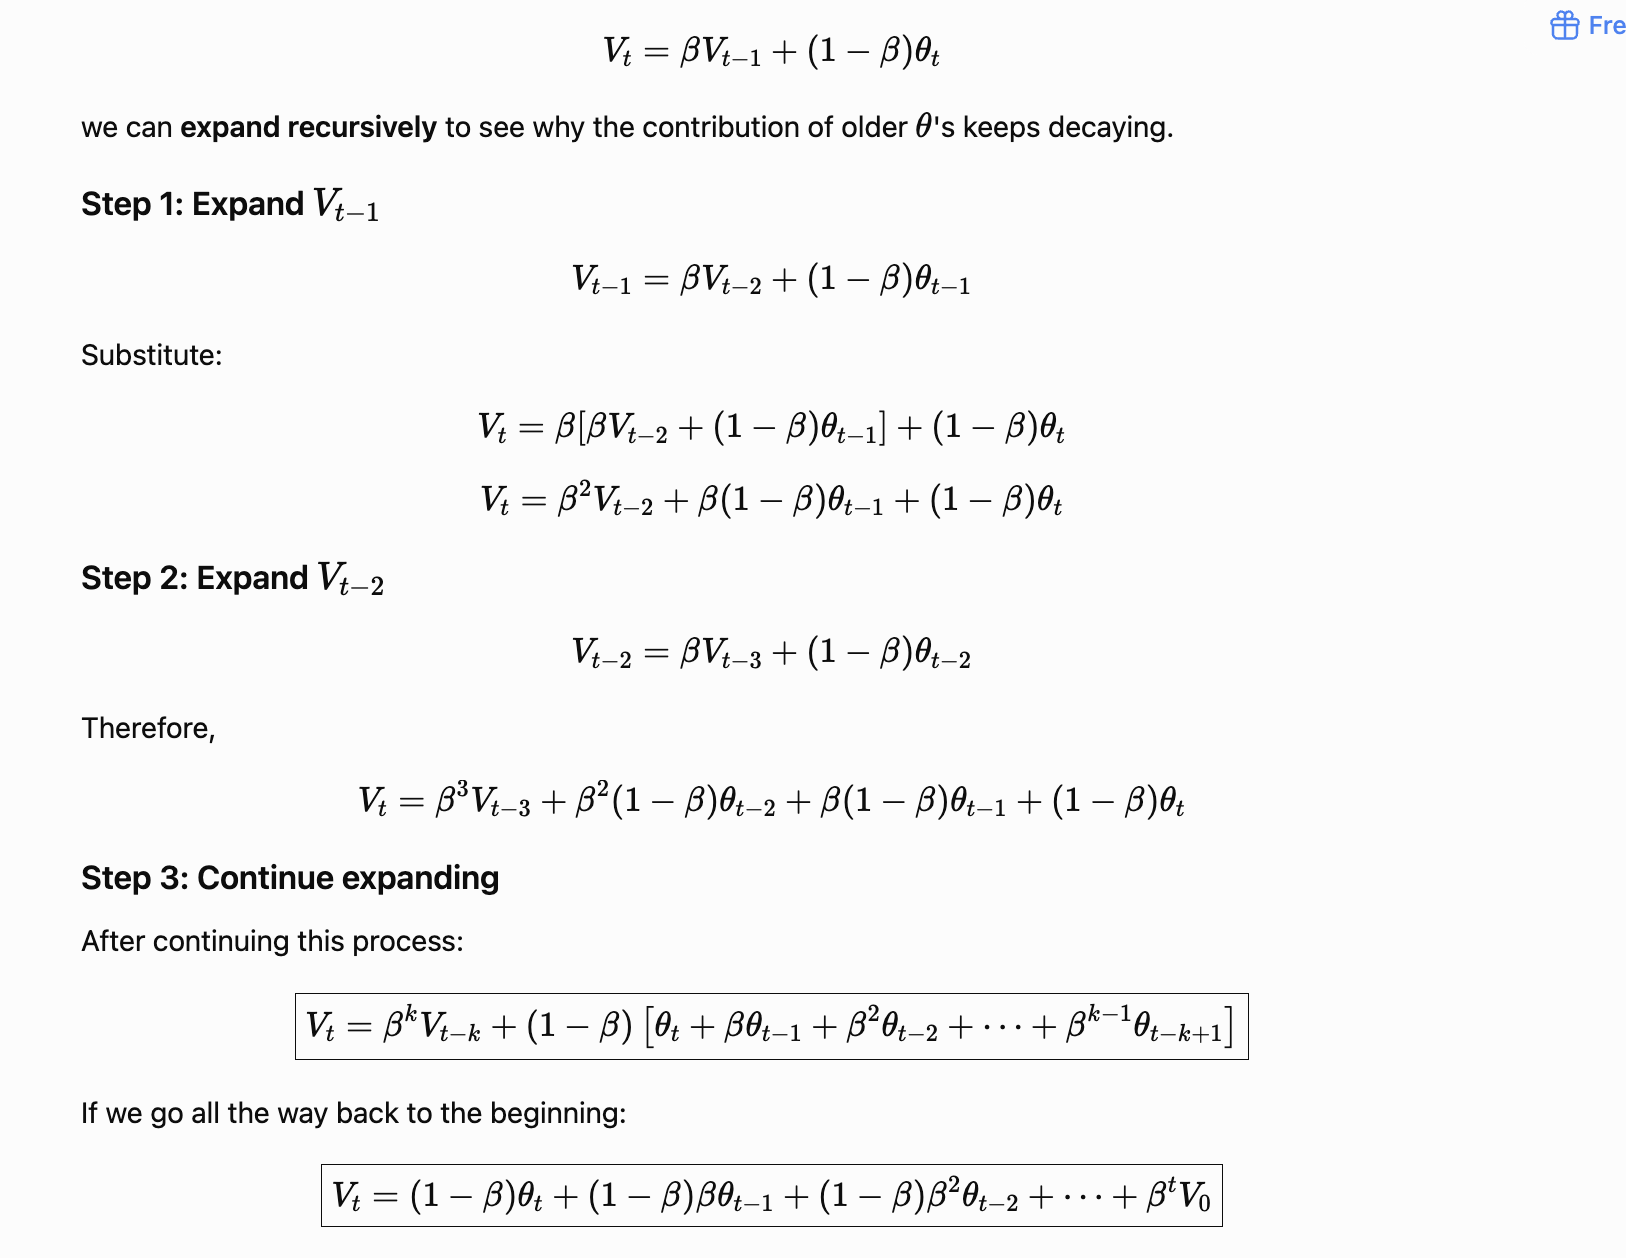

# 2. Momentum

## 2.1 Concept first
### Analogy: a ball rolling downhill
A ball does not forget its previous motion at every instant. It carries **momentum**.

Plain GD:
- follows the current gradient immediately,
- noisy gradients can make the direction jump.

Momentum:
- keeps a **smoothed average of recent gradients**,
- therefore builds a more stable direction,
- reduces zig-zagging in a ravine-shaped loss.

### Key idea
> **Momentum = EWMA of gradients.**

## 2.2 Mathematics
Let

$$g_t = \frac{\partial L}{\partial w}$$

First smooth the gradients:

$$v_t = \beta v_{t-1} + (1-\beta)g_t$$

Then update the weight:

$$w_t = w_{t-1} - \alpha v_t$$

### What changed from GD?
GD uses $g_t$. Momentum uses **$v_t$**, a smoothed version of recent gradients.

> **Framework note:** Some libraries write momentum as $v_t=\beta v_{t-1}+g_t$ and absorb the $(1-\beta)$ scaling into the learning rate. The intuition is the same.

### Why Momentum Can Take Larger Steps

Suppose the gradient remains approximately **10 in the same direction** for several iterations, with:

$$
\beta = 0.9
$$

| Iteration | Normal Gradient Descent uses |        Momentum Velocity |
| --------- | ---------------------------: | -----------------------: |
| 1         |                         $10$ |                     $10$ |
| 2         |                         $10$ |      $0.9(10) + 10 = 19$ |
| 3         |                         $10$ |    $0.9(19) + 10 = 27.1$ |
| 4         |                         $10$ | $0.9(27.1) + 10 = 34.39$ |

So, even though the old gradients are **decayed**, they are still added to the current gradient.

For example, at iteration 3:

$$
v_3 = g_3 + 0.9g_2 + 0.9^2g_1
$$

Substituting the gradient values:

$$
v_3 = 10 + 0.9(10) + 0.9^2(10)
$$

$$
v_3 = 10 + 9 + 8.1 = 27.1
$$

Therefore, when consecutive gradients point in the **same direction**, their contributions accumulate and momentum produces a larger effective update than normal gradient descent.

> **Key idea:** The decay factor reduces the contribution of previous gradients; it does not completely remove them.


## 2.3 One manual calculation
Suppose:

- $w_0=5$
- $v_0=0$
- $\alpha=0.1$
- $\beta=0.9$
- gradients: $g_1=2$, then $g_2=3$

### Step 1
$$v_1=0.9(0)+0.1(2)=0.2$$

$$w_1=5-0.1(0.2)=4.98$$

### Step 2
$$v_2=0.9(0.2)+0.1(3)=0.18+0.30=0.48$$

$$w_2=4.98-0.1(0.48)=4.932$$

**Takeaway:** the update direction now contains information from earlier gradients.

In [ ]:
# Verify the momentum calculation
w, v = 5.0, 0.0
alpha, beta = 0.1, 0.9

for g in [2.0, 3.0]:
    v = beta*v + (1-beta)*g
    w = w - alpha*v
    print(f"gradient={g:.1f}, velocity={v:.3f}, weight={w:.3f}")

# 3. Adagrad — Adaptive Gradient

## 3.1 Concept first
Momentum mainly improves the **direction** by smoothing gradients.

Adagrad asks a different question:
> Why should every weight always receive the same learning rate?

### Main idea
Give **each parameter its own effective learning rate**.

Adagrad remembers how large the gradients for each parameter have been in the past.

- parameter with repeatedly **large gradients** → smaller future steps
- parameter with **small/rare gradients** → relatively larger steps

This is especially intuitive for sparse features.

## 3.2 Mathematics
For each parameter, accumulate squared gradients:

$$s_t = s_{t-1} + g_t^2$$

Then update:

$$
w_t^  =  w_{t-1}- \frac{\alpha}{\sqrt{s_t}+\epsilon}g_t
$$

Here:
- $s_t$ stores the history of **squared gradients**,
- $\epsilon$ is a tiny number that prevents division by zero,
- $\frac{\alpha}{\sqrt{s_t}+\epsilon}$ acts like an **adaptive learning rate**.

> Some textbooks write $\sqrt{s_t+\epsilon}$ instead. The tiny numerical-stability term is placed slightly differently across formulations/implementations; the teaching idea is unchanged.

## 3.3 One manual calculation
Let:

- $w_0=5$
- $s_0=0$
- $\alpha=0.1$
- ignore tiny $\epsilon$ for hand calculation
- $g_1=g_2=2$

### Step 1
$$s_1=0+2^2=4$$

$$w_1=5-0.1\frac{2}{\sqrt4}=5-0.1=4.9$$

### Step 2
$$s_2=4+2^2=8$$

$$w_2=4.9-0.1\frac{2}{\sqrt8}$$

$$w_2\approx4.9-0.0707=4.8293$$

Notice: the second step is already smaller than the first.

In [ ]:
# Verify how Adagrad's step shrinks
import math
w, s = 5.0, 0.0
alpha = 0.1

for g in [2.0, 2.0, 2.0, 2.0]:
    s = s + g**2
    step = alpha * g / math.sqrt(s)
    w = w - step
    print(f"s={s:>4.1f}, step={step:.4f}, weight={w:.4f}")

# 4. Why RMSProp evolved from Adagrad

This is the most important connection to make on the board.

## Adagrad's problem

$$s_t=s_{t-1}+g_t^2$$

The accumulator **only grows**.

Therefore:

$$\text{effective learning rate} \approx \frac{\alpha}{\sqrt{s_t}}$$

keeps becoming smaller and smaller.

After many updates, Adagrad may become **too cautious** and almost stop learning.

## RMSProp's fix
Instead of remembering *all* squared gradients forever, keep an **EWMA of squared gradients**.

### Evolution in one line

**Adagrad:** cumulative sum of $g^2$  
↓ **Problem:** denominator grows forever  
↓ **RMSProp:** exponentially forget old $g^2$

# 5. RMSProp

## 5.1 Concept first
RMSProp keeps Adagrad's idea of **adaptive step sizes**, but changes the memory.

Adagrad remembers all squared gradients equally.

RMSProp says:
> Recent squared gradients should matter more; very old ones should fade away.

So it applies EWMA to $g_t^2$.

## 5.2 Mathematics

$$s_t = \beta s_{t-1} + (1-\beta)g_t^2$$

$$w_t = w_{t-1} - \alpha\frac{g_t}{\sqrt{s_t}+\epsilon}$$

Compare directly:

| Optimizer | Memory of squared gradients |
|---|---|
| Adagrad | $s_t=s_{t-1}+g_t^2$ |
| RMSProp | $s_t=\beta s_{t-1}+(1-\beta)g_t^2$ |

**That one change is the core evolution from Adagrad to RMSProp.**

## 5.3 One manual calculation
Let:

- $w_0=5$
- $s_0=0$
- $\alpha=0.01$
- $\beta=0.9$
- $g_1=g_2=2$
- ignore tiny $\epsilon$ for hand calculation

### Step 1
$$s_1=0.9(0)+0.1(2^2)=0.4$$

$$w_1=5-0.01\frac{2}{\sqrt{0.4}}\approx4.9684$$

### Step 2
$$s_2=0.9(0.4)+0.1(4)=0.76$$

$$w_2=4.9684-0.01\frac{2}{\sqrt{0.76}}\approx4.9455$$

Unlike Adagrad, $s_t$ does not have to grow without bound; old squared gradients gradually lose influence.

In [ ]:
# Compare the accumulator for a constant gradient: Adagrad vs RMSProp
import math

g = 2.0
beta = 0.9
s_ada = 0.0
s_rms = 0.0

print("step | Adagrad s | RMSProp s")
for t in range(1, 11):
    s_ada = s_ada + g**2
    s_rms = beta*s_rms + (1-beta)*g**2
    print(f"{t:>4} | {s_ada:>9.3f} | {s_rms:>9.3f}")

# 6. Adam — Adaptive Moment Estimation

## 6.1 Build Adam from ideas we already know
Students do **not** need a completely new mental model.

We already have:

### Momentum
EWMA of gradients → smooth **direction**

$$v_t=\beta_1v_{t-1}+(1-\beta_1)g_t$$

### RMSProp
EWMA of squared gradients → adaptive **step size**

$$s_t=\beta_2s_{t-1}+(1-\beta_2)g_t^2$$

### Adam
Put both together:

> **Adam ≈ Momentum in the numerator + RMSProp in the denominator.**

So Adam tracks:
- first moment: average gradient $m_t$
- second raw moment: average squared gradient $v_t$

## 6.2 Full Adam mathematics

First moment:

$$v_t=\beta_1v_{t-1}+(1-\beta_1)g_t$$

Second moment:

$$s_t=\beta_2s_{t-1}+(1-\beta_2)g_t^2$$

Because both start from zero, early values are biased toward zero. Adam corrects this:

$$\hat v_t=\frac{v_t}{1-\beta_1^t}$$

$$\hat s_t=\frac{s_t}{1-\beta_2^t}$$

Finally:

$$w_t=w_{t-1}-\alpha\frac{\hat v_t}{\sqrt{\hat s_t}+\epsilon}$$

Common default ideas:
- $\beta_1\approx0.9$ → gradient memory
- $\beta_2\approx0.999$ → squared-gradient memory
- $\epsilon$ → numerical stability

### Bias Correction in Adam

In Adam, we use:

$$
\hat{v}_t = \frac{v_t}{1-\beta_1^t}
$$

and

$$
\hat{s}_t = \frac{s_t}{1-\beta_2^t}
$$

These are called **bias-corrected estimates**.

---

### What is \(t\)?

Here,

$$
t = \text{current optimization step or iteration number}
$$

For example:

* First update → $t=1$
* Second update → $t=2$
* Third update → $t=3$

So if:

$$
\beta_1 = 0.9
$$

then:

$$
\beta_1^1 = 0.9
$$

$$
\beta_1^2 = 0.81
$$

$$
\beta_1^3 = 0.729
$$

Therefore, \(t\) simply tells Adam **which update number we are currently performing**.

---

### Why do we need bias correction?

Both the Momentum term and RMSProp term are initialized with zero:

$$
v_0 = 0
$$

$$
s_0 = 0
$$

Because they start from zero, their values during the first few iterations become **artificially smaller than they should be**.

This is called **bias toward zero**.

---

### Example: Momentum Term

The Momentum component is:

$$
v_t = \beta_1 v_{t-1} + (1-\beta_1)g_t
$$

Suppose:

$$
\beta_1 = 0.9
$$

$$
v_0 = 0
$$

and the first gradient is:

$$
g_1 = 10
$$

Then:

$$
v_1 = 0.9(0) + (1-0.9)(10)
$$

$$
v_1 = 0 + 0.1(10)
$$

$$
v_1 = 1
$$

But the actual gradient was:

$$
g_1 = 10
$$

while the Momentum estimate became only:

$$
v_1 = 1
$$

This happened because we started with:

$$
v_0 = 0
$$

So the first estimate is pulled strongly toward zero.

Adam corrects this using:

$$
\hat{v}_1 = \frac{v_1}{1-\beta_1^1}
$$

Substituting the values:

$$
\hat{v}_1 = \frac{1}{1-0.9}
$$

$$
\hat{v}_1 = \frac{1}{0.1}
$$

$$
\hat{v}_1 = 10
$$

So after bias correction:

$$
\boxed{\hat{v}_1 = 10}
$$

---

### Example: RMSProp Term

The RMSProp component is:

$$
s_t = \beta_2 s_{t-1} + (1-\beta_2)g_t^2
$$

Suppose:

$$
\beta_2 = 0.999
$$

$$
s_0 = 0
$$

and:

$$
g_1 = 10
$$

Then:

$$
s_1 = 0.999(0) + (1-0.999)(10^2)
$$

$$
s_1 = 0.001(100)
$$

$$
s_1 = 0.1
$$

But the actual squared gradient is:

$$
g_1^2 = 100
$$

So again, the estimate is much smaller because we started from zero.

Adam corrects it using:

$$
\hat{s}_1 = \frac{s_1}{1-\beta_2^1}
$$

$$
\hat{s}_1 = \frac{0.1}{1-0.999}
$$

$$
\hat{s}_1 = \frac{0.1}{0.001}
$$

$$
\hat{s}_1 = 100
$$

Therefore:

$$
\boxed{\hat{s}_1 = 100}
$$

---

### Why is Bias Correction Mainly Important in Early Iterations?

Consider:

$$
1-\beta^t
$$

During the first few iterations, \(t\) is small, so:

$$
\beta^t
$$

is still relatively large.

Therefore, the correction has a significant effect.

But as the number of iterations increases:

$$
t \rightarrow \text{large}
$$

then:

$$
\beta^t \rightarrow 0
$$

and therefore:

$$
1-\beta^t \rightarrow 1
$$

So eventually:

$$
\hat{v}_t \approx v_t
$$

and:

$$
\hat{s}_t \approx s_t
$$

This means bias correction is mainly important during the **initial training steps**.

---

### Key Idea

$$
\boxed{
\text{Start from zero}
\rightarrow
\text{early estimates become too small}
\rightarrow
\text{divide by }(1-\beta^t)
\rightarrow
\text{correct the estimates}
}
$$

> **Remember:** Bias correction does not change the main idea of Momentum or RMSProp. It only corrects the artificial effect caused by initializing \(v_0\) and \(s_0\) to zero.


## 6.3 One manual Adam calculation
Let:

- $w_0=5$
- $m_0=0$, $v_0=0$
- $g_1=2$
- $\alpha=0.001$
- $\beta_1=0.9$
- $\beta_2=0.999$
- ignore tiny $\epsilon$ for hand calculation

### First moment
$$m_1=0.9(0)+0.1(2)=0.2$$

### Second moment
$$v_1=0.999(0)+0.001(2^2)=0.004$$

### Bias correction
$$\hat m_1=\frac{0.2}{1-0.9}=2$$

$$\hat v_1=\frac{0.004}{1-0.999}=4$$

### Weight update
$$w_1=5-0.001\frac{2}{\sqrt4}=5-0.001=4.999$$

### Board summary
**Momentum asks:** what direction have gradients been consistently pointing?  
**RMSProp asks:** how large have gradients recently been?  
**Adam uses both answers.**

In [ ]:
# Verify the first Adam update
w = 5.0
m = 0.0
v = 0.0
g = 2.0
alpha = 0.001
beta1 = 0.9
beta2 = 0.999
t = 1

m = beta1*m + (1-beta1)*g
v = beta2*v + (1-beta2)*(g**2)
m_hat = m / (1-beta1**t)
v_hat = v / (1-beta2**t)
w = w - alpha * m_hat / (v_hat**0.5)

print("m     =", m)
print("v     =", v)
print("m_hat =", m_hat)
print("v_hat =", v_hat)
print("w_new =", w)

# 7. The complete evolution — one board diagram

```text
Normal GD
   |
   |  current gradient can oscillate / be noisy
   v
Momentum
   = EWMA(gradient)
   = smoother direction

Adagrad
   = accumulate gradient²
   = separate effective LR for each parameter
   |
   |  accumulator keeps growing -> LR may become too small
   v
RMSProp
   = EWMA(gradient²)
   = Adagrad idea + forgetting old squared gradients
   |
   |  add Momentum-like first-moment information
   v
Adam
   = EWMA(gradient) / sqrt(EWMA(gradient²))
   + bias correction
```

### Formula pattern to remember

- **Momentum:** $\text{EWMA}(g)$
- **Adagrad:** $g/\sqrt{\sum g^2}$
- **RMSProp:** $g/\sqrt{\text{EWMA}(g^2)}$
- **Adam:** $\text{EWMA}(g)/\sqrt{\text{EWMA}(g^2)}$

# 8. GIF visualizer — compare with normal GD

We use a deliberately **ravine-shaped loss**:

$$L(w_1,w_2)=w_1^2+25w_2^2$$

The $w_2$ direction is much steeper than the $w_1$ direction. This makes plain GD zig-zag, so the optimizer behavior is easy to see.

> **Teaching note:** Learning rates below are chosen to make each trajectory visible and educational. This GIF is an intuition demo, not a controlled benchmark of equal hyperparameters.

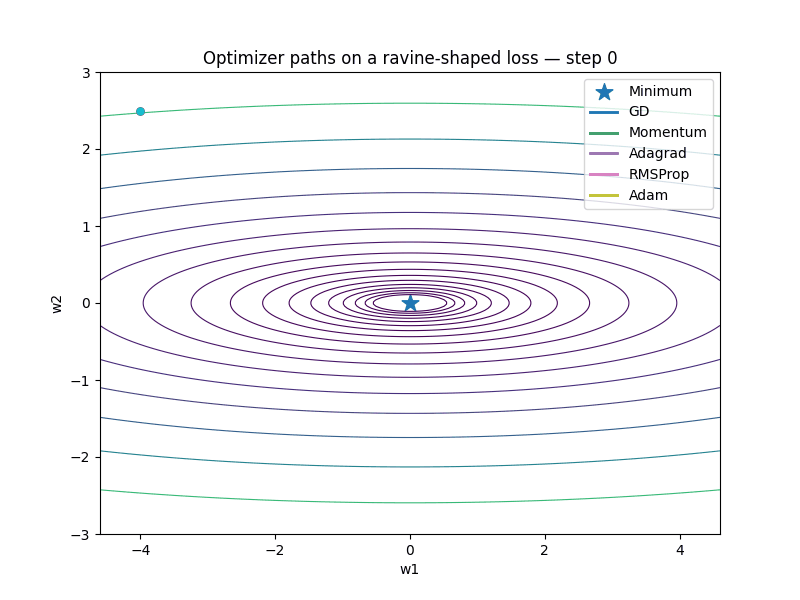

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

# Loss: L = w1^2 + 25*w2^2
def grad(p):
    w1, w2 = p
    return np.array([2*w1, 50*w2], dtype=float)

def run_optimizer(method, lr, steps=80,
                  beta=0.9, beta1=0.9, beta2=0.999, eps=1e-8):
    p = np.array([-4.0, 2.5], dtype=float)
    path = [p.copy()]
    m = np.zeros(2)
    s = np.zeros(2)

    for t in range(1, steps+1):
        g = grad(p)

        if method == "GD":
            p -= lr * g

        elif method == "Momentum":
            m = beta*m + (1-beta)*g
            p -= lr*m

        elif method == "Adagrad":
            s += g*g
            p -= lr*g/(np.sqrt(s) + eps)

        elif method == "RMSProp":
            s = beta*s + (1-beta)*(g*g)
            p -= lr*g/(np.sqrt(s) + eps)

        elif method == "Adam":
            m = beta1*m + (1-beta1)*g
            s = beta2*s + (1-beta2)*(g*g)
            m_hat = m/(1-beta1**t)
            s_hat = s/(1-beta2**t)
            p -= lr*m_hat/(np.sqrt(s_hat) + eps)

        path.append(p.copy())

    return np.array(path)

# Method-specific learning rates chosen for a clear classroom animation
params = {
    "GD": 0.035,
    "Momentum": 0.06,
    "Adagrad": 0.8,
    "RMSProp": 0.15,
    "Adam": 0.18,
}

paths = {name: run_optimizer(name, lr) for name, lr in params.items()}

# Background loss contours
x = np.linspace(-4.6, 4.6, 220)
y = np.linspace(-3.0, 3.0, 220)
X, Y = np.meshgrid(x, y)
Z = X**2 + 25*Y**2

fig, ax = plt.subplots(figsize=(8, 6))
levels = np.geomspace(0.3, 250, 18)
ax.contour(X, Y, Z, levels=levels, linewidths=0.8)
ax.scatter([0], [0], marker="*", s=160, label="Minimum")

lines, points = {}, {}
for name, path in paths.items():
    line, = ax.plot([], [], lw=2, label=name)
    point, = ax.plot([], [], marker="o", markersize=5)
    lines[name] = line
    points[name] = point

ax.set_xlim(-4.6, 4.6)
ax.set_ylim(-3.0, 3.0)
ax.set_xlabel("w1")
ax.set_ylabel("w2")
ax.legend(loc="upper right")

def update(frame):
    for name, path in paths.items():
        upto = min(frame + 1, len(path))
        lines[name].set_data(path[:upto, 0], path[:upto, 1])
        points[name].set_data([path[upto-1, 0]], [path[upto-1, 1]])
    ax.set_title(f"Optimizer paths on a ravine-shaped loss — step {frame}")
    return list(lines.values()) + list(points.values())

anim = FuncAnimation(fig, update, frames=81, interval=120, blit=False)
anim.save("optimizer_comparison_gd.gif", writer=PillowWriter(fps=8))
plt.close(fig)

display(Image(filename="optimizer_comparison_gd.gif"))

## What should students observe in the GIF?

1. **GD:** zig-zags strongly across the steep direction.
2. **Momentum:** uses gradient history, so movement is smoother and has inertia.
3. **Adagrad:** adapts step sizes using accumulated squared gradients.
4. **RMSProp:** uses recent squared gradients instead of an ever-growing total.
5. **Adam:** combines a smoothed direction with adaptive scaling.

### Ask the class
> If the valley is steep vertically but shallow horizontally, why is one fixed learning rate awkward for both directions?

# 9. Apply optimizers to a real toy dataset

We will use the **two-moons classification dataset** because:
- it is small and fast,
- it is nonlinear,
- students can see why a neural network is needed,
- optimizer code stays very simple.

We will train the **same neural-network architecture** with different optimizers.

In [ ]:
# Imports and dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = make_moons(n_samples=1200, noise=0.22, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

plt.figure(figsize=(7, 5))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=18)
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title("Two-moons training data")
plt.show()

## 9.1 Build one tiny neural network

The architecture is intentionally simple. The optimizer is the only thing we will change.

In [ ]:
import tensorflow as tf

# Reproducibility
tf.keras.utils.set_random_seed(42)

def build_model():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(2,)),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

model = build_model()
model.summary()

# 10. How to apply an optimizer in Keras

The important line is simply:

```python
optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)
model.compile(optimizer=optimizer, ...)
```

The neural network and backpropagation produce gradients. The optimizer decides **how those gradients update the weights**.

## 10.1 Momentum in code

In Keras, Momentum is used through SGD with a momentum value:

In [ ]:
optimizer = tf.keras.optimizers.SGD(
    learning_rate=0.05,
    momentum=0.9
)

## 10.2 Adagrad in code

In [ ]:
optimizer = tf.keras.optimizers.Adagrad(
    learning_rate=0.05
)

## 10.3 RMSProp in code

`rho` plays the role of the squared-gradient EWMA decay factor.

In [ ]:
optimizer = tf.keras.optimizers.RMSprop(
    learning_rate=0.01,
    rho=0.9
)

## 10.4 Adam in code

`beta_1` controls the first moment (gradient EWMA).  
`beta_2` controls the second moment (squared-gradient EWMA).

In [ ]:
optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.01,
    beta_1=0.9,
    beta_2=0.999
)

# 11. Train once with Adam — complete minimal example

This is the smallest end-to-end code students need to remember.

In [ ]:
tf.keras.utils.set_random_seed(42)

model = build_model()
optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)

model.compile(
    optimizer=optimizer,
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=32,
    verbose=0
)

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.3f}")

# 12. Fair classroom comparison: same model, different optimizers

To make the comparison more meaningful:
- use the same dataset,
- use the same architecture,
- start from the same initial weights,
- use the same number of epochs and batch size.

**Important:** optimizer learning rates are hyperparameters. Different optimizers often need different good values, so do not interpret this toy run as a universal ranking.

In [ ]:
# Create one set of initial weights and reuse it for every optimizer

tf.keras.utils.set_random_seed(42)
base_model = build_model()
initial_weights = base_model.get_weights()

optimizer_factories = {
    "SGD": lambda: tf.keras.optimizers.SGD(learning_rate=0.05),
    "Momentum": lambda: tf.keras.optimizers.SGD(learning_rate=0.05, momentum=0.9),
    "Adagrad": lambda: tf.keras.optimizers.Adagrad(learning_rate=0.05),
    "RMSProp": lambda: tf.keras.optimizers.RMSprop(learning_rate=0.01, rho=0.9),
    "Adam": lambda: tf.keras.optimizers.Adam(learning_rate=0.01),
}

histories = {}
results = []

for name, make_optimizer in optimizer_factories.items():
    tf.keras.utils.set_random_seed(42)
    model = build_model()
    model.set_weights(initial_weights)

    model.compile(
        optimizer=make_optimizer(),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    h = model.fit(
        X_train, y_train,
        validation_split=0.2,
        epochs=40,
        batch_size=32,
        verbose=0
    )

    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    histories[name] = h.history
    results.append([name, test_loss, test_acc])

results_df = pd.DataFrame(results, columns=["Optimizer", "Test Loss", "Test Accuracy"])
results_df.sort_values("Test Accuracy", ascending=False)

## 12.1 Compare validation-loss curves

Look at **how quickly** each optimizer reduces loss, not only the final accuracy.

In [ ]:
plt.figure(figsize=(8, 5))
for name, history in histories.items():
    plt.plot(history["val_loss"], label=name)

plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Optimizer comparison on the same neural network")
plt.legend()
plt.show()

# 13. Final comparison table

| Optimizer | What it remembers | Main benefit | Main caution |
|---|---|---|---|
| GD / SGD | current gradient | simple baseline | may zig-zag / noisy |
| Momentum | EWMA of gradients | smoother direction, inertia | adds momentum hyperparameter |
| Adagrad | cumulative squared gradients | per-parameter adaptive LR | LR can shrink too much |
| RMSProp | EWMA of squared gradients | fixes Adagrad's ever-growing memory | still has no first-moment direction smoothing by itself |
| Adam | EWMA of gradients **and** squared gradients | momentum + adaptive scaling | still needs sensible LR / validation |

## The four sentences students should leave with
1. **Momentum** smooths gradients.
2. **Adagrad** adapts the learning rate using accumulated squared gradients.
3. **RMSProp** fixes Adagrad by forgetting old squared gradients.
4. **Adam** combines Momentum-like first-moment smoothing with RMSProp-like second-moment scaling, plus bias correction.

# 14. Quick class check

Ask students without looking above:

1. Why can GD zig-zag in a narrow valley?
2. Which quantity is averaged in Momentum: $g$ or $g^2$?
3. Why can Adagrad's learning rate become extremely small?
4. What single change converts the Adagrad idea into the RMSProp idea?
5. In Adam, what is stored in $m_t$ and $v_t$?
6. Where do you change the optimizer in Keras code?

### 30-second memory trick
- **Momentum:** remember **direction**
- **Adagrad:** remember **all squared gradients**
- **RMSProp:** remember **recent squared gradients**
- **Adam:** remember **recent gradients + recent squared gradients**

# 15. References / instructor notes

- Instructor handwritten notes supplied with this class asset (EWMA, Momentum, Adagrad, RMSProp, Adam progression).
- Duchi, Hazan & Singer (2011), *Adaptive Subgradient Methods for Online Learning and Stochastic Optimization*, JMLR: https://jmlr.org/papers/v12/duchi11a.html
- Kingma & Ba, *Adam: A Method for Stochastic Optimization*: https://arxiv.org/abs/1412.6980
- TensorFlow/Keras optimizer API: https://www.tensorflow.org/api_docs/python/tf/keras/optimizers

### Teacher note
RMSProp is best presented here as a **pedagogical evolution of Adagrad**: replace the cumulative squared-gradient sum with an exponentially weighted average. Adam is best presented as **RMSProp-style adaptive scaling + Momentum-style first-moment smoothing**, then reveal bias correction.